In [1]:
import pandas as pd
import plotly.graph_objects as go

from plotly.subplots import make_subplots

In [3]:
df = pd.read_csv("index_1.csv")

In [4]:
df

,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.70,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.70,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.70,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.90,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.70,Latte
...,...,...,...,...,...,...
3631,2025-03-23,2025-03-23 10:34:54.894,card,ANON-0000-0000-1158,35.76,Cappuccino
3632,2025-03-23,2025-03-23 14:43:37.362,card,ANON-0000-0000-1315,35.76,Cocoa
3633,2025-03-23,2025-03-23 14:44:16.864,card,ANON-0000-0000-1315,35.76,Cocoa
3634,2025-03-23,2025-03-23 15:47:28.723,card,ANON-0000-0000-1316,25.96,Americano


In [15]:

df['Month'] = df['date'].dt.strftime('%b')


In [30]:
month = df["Month"].unique()
month

array(['Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov',
       'Dec', 'Jan', 'Feb'], dtype=object)

In [28]:
coffee_name = df['coffee_name'].unique()
coffee_name


array(['Latte', 'Hot Chocolate', 'Americano', 'Americano with Milk',
       'Cocoa', 'Cortado', 'Espresso', 'Cappuccino'], dtype=object)

In [38]:
month_wise_revenue = df.groupby("Month")["money"].sum().reset_index()
month_wise_revenue

,Month,money
0,Apr,6720.56
1,Aug,7613.84
2,Dec,8237.74
3,Feb,13215.48
4,Jan,6398.86
5,Jul,6915.94
6,Jun,7758.76
7,Mar,17036.64
8,May,9063.42
9,Nov,8590.54


In [50]:
df["datetime"] = pd.to_datetime(df["datetime"])

df["Hours"] = df["datetime"].dt.hour

In [51]:
time = df["Hours"].unique()
time

array([10, 12, 13, 15, 16, 18, 19, 11, 14, 17,  9,  7, 20,  8, 22, 21,  6],
      dtype=int32)

In [55]:
df["Hours"] = df["datetime"].dt.hour

def get_time_period(hour):
    if 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df["Time_Period"] = df["Hours"].apply(get_time_period)

In [56]:
time_coffee = (
    df.groupby(["Time_Period", "coffee_name"])
      .size()
      .reset_index(name="Orders")
)
time_coffee

,Time_Period,coffee_name,Orders
0,Afternoon,Americano,239
1,Afternoon,Americano with Milk,244
2,Afternoon,Cappuccino,169
3,Afternoon,Cocoa,77
4,Afternoon,Cortado,91
5,Afternoon,Espresso,58
6,Afternoon,Hot Chocolate,82
7,Afternoon,Latte,272
8,Evening,Americano,90
9,Evening,Americano with Milk,165


In [61]:
Income_Method_and_Income = df.groupby("cash_type")["money"].sum().reset_index()
Income_Method_and_Income

,cash_type,money
0,card,112245.58
1,cash,3186.00


In [58]:
coffee_sales = df.groupby("coffee_name")["money"].sum().reset_index()
coffee_sales

,coffee_name,money
0,Americano,15062.26
1,Americano with Milk,25269.12
2,Cappuccino,18034.14
3,Cocoa,8678.16
4,Cortado,7534.86
5,Espresso,2814.28
6,Hot Chocolate,10172.46
7,Latte,27866.30


In [33]:
df["datetime"] = pd.to_datetime(df["datetime"])

df["Year"] = df["datetime"].dt.year

In [35]:
df["Year"].unique()

array([2024, 2025], dtype=int32)

In [37]:
year_wise_sales = df.groupby("Year")["money"].sum().reset_index()
year_wise_sales

,Year,money
0,2024,85830.80
1,2025,29600.78


In [46]:
sales_2024 = df[df["Year"] == 2024].groupby(
    ["Month", "coffee_name"]
)["money"].sum().reset_index()
sales_2024

,Month,coffee_name,money
0,Apr,Americano,1001.94
1,Apr,Americano with Milk,1407.74
2,Apr,Cappuccino,1659.44
3,Apr,Cocoa,232.82
4,Apr,Cortado,548.48
...,...,...,...
75,Sep,Cocoa,298.32
76,Sep,Cortado,961.46
77,Sep,Espresso,217.44
78,Sep,Hot Chocolate,366.90


In [47]:
sales_2025 = df[df["Year"] == 2025].groupby(
    ["Month", "coffee_name"]
)["money"].sum().reset_index()
sales_2025

,Month,coffee_name,money
0,Feb,Americano,3037.32
1,Feb,Americano with Milk,2623.10
2,Feb,Cappuccino,1859.52
3,Feb,Cocoa,2002.56
4,Feb,Cortado,259.60
5,Feb,Espresso,358.02
6,Feb,Hot Chocolate,1144.32
7,Feb,Latte,1931.04
8,Jan,Americano,649.00
9,Jan,Americano with Milk,1604.72


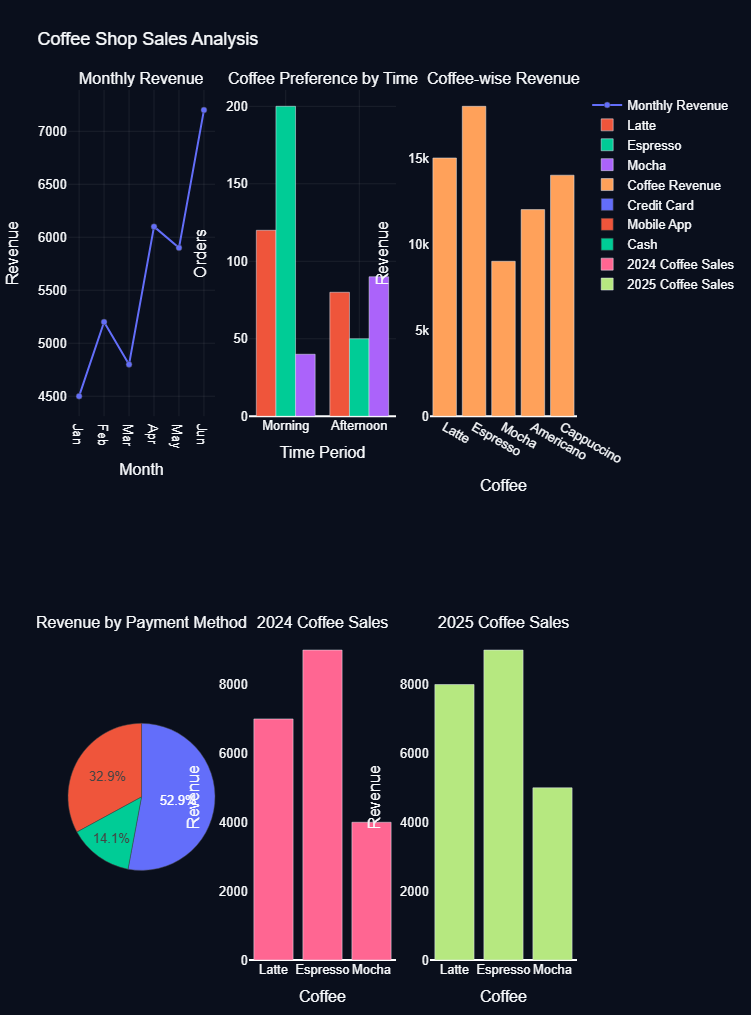

In [72]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# =========================================================
# 0. MOCK DATA GENERATION (Replaces missing variables)
# =========================================================
month_wise_revenue = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
    "money": [4500, 5200, 4800, 6100, 5900, 7200]
})

time_coffee = pd.DataFrame({
    "coffee_name": ["Latte", "Latte", "Espresso", "Espresso", "Mocha", "Mocha"],
    "Time_Period": ["Morning", "Afternoon", "Morning", "Afternoon", "Morning", "Afternoon"],
    "Orders": [120, 80, 200, 50, 40, 90]
})
df = time_coffee.copy() # Required for df["coffee_name"].unique()

coffee_sales = pd.DataFrame({
    "coffee_name": ["Latte", "Espresso", "Mocha", "Americano", "Cappuccino"],
    "money": [15000, 18000, 9000, 12000, 14000]
})

Income_Method_and_Income = pd.DataFrame({
    "cash_type": ["Credit Card", "Cash", "Mobile App"],
    "money": [45000, 12000, 28000]
})

sales_2024 = pd.DataFrame({
    "coffee_name": ["Latte", "Espresso", "Mocha"],
    "money": [7000, 9000, 4000]
})

sales_2025 = pd.DataFrame({
    "coffee_name": ["Latte", "Espresso", "Mocha"],
    "money": [8000, 9000, 5000]
})

# =========================================================
# 1. CREATE SUBPLOTS
# =========================================================
fig = make_subplots(
    rows=2,
    cols=3,
    subplot_titles=(
        "Monthly Revenue",
        "Coffee Preference by Time",
        "Coffee-wise Revenue",
        "Revenue by Payment Method",
        "2024 Coffee Sales",
        "2025 Coffee Sales"
    ),
    specs=[
        [{"type": "xy"}, {"type": "xy"}, {"type": "xy"}],
        [{"type": "domain"}, {"type": "xy"}, {"type": "xy"}]
    ]
)

# =========================================================
# 2. ADD TRACES
# =========================================================

# Row 1, Col 1: MONTH WISE REVENUE
fig.add_trace(
    go.Scatter(
        x=month_wise_revenue["Month"],
        y=month_wise_revenue["money"],
        name="Monthly Revenue",
        mode="lines+markers"
    ),
    row=1, col=1
)

# Row 1, Col 2: COFFEE PREFERENCE BY TIME
for coffee in df["coffee_name"].unique():
    data = time_coffee[time_coffee["coffee_name"] == coffee]
    fig.add_trace(
        go.Bar(
            x=data["Time_Period"],
            y=data["Orders"],
            name=coffee
        ),
        row=1, col=2
    )

# Row 1, Col 3: COFFEE-WISE REVENUE
fig.add_trace(
    go.Bar(
        x=coffee_sales["coffee_name"],
        y=coffee_sales["money"],
        name="Coffee Revenue"
    ),
    row=1, col=3
)

# Row 2, Col 1: REVENUE BY PAYMENT METHOD
fig.add_trace(
    go.Pie(
        labels=Income_Method_and_Income["cash_type"],
        values=Income_Method_and_Income["money"],
        name="Payment Method"
    ),
    row=2, col=1
)

# Row 2, Col 2: 2024 COFFEE SALES
fig.add_trace(
    go.Bar(
        x=sales_2024["coffee_name"],
        y=sales_2024["money"],
        name="2024 Coffee Sales"
    ),
    row=2, col=2
)

# Row 2, Col 3: 2025 COFFEE SALES
fig.add_trace(
    go.Bar(
        x=sales_2025["coffee_name"],
        y=sales_2025["money"],
        name="2025 Coffee Sales"
    ),
    row=2, col=3
)

# =========================================================
# 3. TRACE & AXIS STYLING
# =========================================================

fig.update_traces(marker=dict(line=dict(width=0.5)))

# X-Axis Settings
fig.update_xaxes(title="Month", showgrid=True, gridwidth=0.5, gridcolor="rgba(255,255,255,0.15)", row=1, col=1)
fig.update_xaxes(title="Time Period", showgrid=True, gridwidth=0.5, gridcolor="rgba(255,255,255,0.15)", row=1, col=2)
fig.update_xaxes(title="Coffee", showgrid=False, row=1, col=3)
fig.update_xaxes(title="Coffee", showgrid=False, row=2, col=2)
fig.update_xaxes(title="Coffee", showgrid=False, row=2, col=3)

# Y-Axis Settings
fig.update_yaxes(title="Revenue", showgrid=True, gridwidth=0.5, gridcolor="rgba(255,255,255,0.15)", row=1, col=1)
fig.update_yaxes(title="Orders", showgrid=True, gridwidth=0.5, gridcolor="rgba(255,255,255,0.15)", row=1, col=2)
fig.update_yaxes(title="Revenue", showgrid=False, row=1, col=3)
fig.update_yaxes(title="Revenue", showgrid=False, row=2, col=2)
fig.update_yaxes(title="Revenue", showgrid=False, row=2, col=3)

# =========================================================
# 4. FINAL DASHBOARD LAYOUT
# =========================================================

fig.update_layout(
    title="Coffee Shop Sales Analysis",
    width=1300,
    height=1000,
    paper_bgcolor="#0A0F1C",
    plot_bgcolor="#0A0F1C",
    font=dict(
        family="Arial",
        size=13,
        color="#F8FAFC"
    ),
    margin=dict(l=50, r=50, t=90, b=50),
    barmode="group",
    showlegend=True
)

fig.show()

In [67]:
sales_2025

,Month,coffee_name,money
0,Feb,Americano,3037.32
1,Feb,Americano with Milk,2623.10
2,Feb,Cappuccino,1859.52
3,Feb,Cocoa,2002.56
4,Feb,Cortado,259.60
5,Feb,Espresso,358.02
6,Feb,Hot Chocolate,1144.32
7,Feb,Latte,1931.04
8,Jan,Americano,649.00
9,Jan,Americano with Milk,1604.72
